In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
rng = np.random.default_rng(42)

dates = pd.date_range("2023-01-01", "2025-12-31", freq="D")

products = {
    "Electronics": [("Headphones", 1500, 900),
                    ("Keyboard", 800, 450),
                    ("Mouse", 500, 250)],
    "Clothing": [("T-Shirt", 500, 250),
                 ("Jeans", 1200, 700),
                 ("Hoodie", 1800, 1000)],
    "Home": [("Lamp", 700, 350),
             ("Bottle", 300, 120),
             ("Storage Box", 450, 200)],
    "Sports": [("Yoga Mat", 900, 450),
               ("Cricket Bat", 2000, 1200),
               ("Skipping Rope", 250, 100)]
}

regions = ["North", "South", "East", "West", "Central"]
rows = []
order_id = 1001

for date in dates:
    number_of_orders = rng.poisson(20) + 5

    for _ in range(number_of_orders):
        category = rng.choice(list(products.keys()))
        product, price, cost = products[category][
            rng.integers(len(products[category]))
        ]

        quantity = int(rng.integers(1, 5))
        unit_price = round(price * rng.uniform(0.9, 1.1), 2)
        unit_cost = cost
        sales = round(quantity * unit_price, 2)
        profit = round(quantity * (unit_price - unit_cost), 2)

        rows.append({
            "Order_ID": f"ORD{order_id}",
            "Order_Date": date,
            "Customer_ID": f"C{rng.integers(1000, 1500)}",
            "Region": rng.choice(regions),
            "Category": category,
            "Product": product,
            "Quantity": quantity,
            "Unit_Price": unit_price,
            "Unit_Cost": unit_cost,
            "Sales": sales,
            "Profit": profit
        })

        order_id += 1

df = pd.DataFrame(rows)

print("Dataset created successfully!")
print("Total transactions:", len(df))
df.head()

Dataset created successfully!
Total transactions: 27341


,Order_ID,Order_Date,Customer_ID,Region,Category,Product,Quantity,Unit_Price,Unit_Cost,Sales,Profit
0,ORD1001,2023-01-01,C1348,East,Clothing,Hoodie,1,1653.90,1000,1653.90,653.90
1,ORD1002,2023-01-01,C1256,North,Sports,Skipping Rope,4,264.30,100,1057.20,657.20
2,ORD1003,2023-01-01,C1185,West,Sports,Cricket Bat,3,2170.71,1200,6512.13,2912.13
3,ORD1004,2023-01-01,C1225,South,Home,Bottle,4,296.60,120,1186.40,706.40
4,ORD1005,2023-01-01,C1031,South,Electronics,Keyboard,4,852.42,450,3409.68,1609.68


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (27341, 11)

Column names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Region', 'Category', 'Product', 'Quantity', 'Unit_Price', 'Unit_Cost', 'Sales', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27341 entries, 0 to 27340
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Order_ID     27341 non-null  object        
 1   Order_Date   27341 non-null  datetime64[ns]
 2   Customer_ID  27341 non-null  object        
 3   Region       27341 non-null  object        
 4   Category     27341 non-null  object        
 5   Product      27341 non-null  object        
 6   Quantity     27341 non-null  int64         
 7   Unit_Price   27341 non-null  float64       
 8   Unit_Cost    27341 non-null  int64         
 9   Sales        27341 non-null  float64       
 10  Profit       27341 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(2), object(5

,Order_Date,Quantity,Unit_Price,Unit_Cost,Sales,Profit
count,27341,27341.000000,27341.000000,27341.000000,27341.000000,27341.000000
mean,2024-06-27 14:14:19.807614720,2.493179,909.476044,498.191727,2273.583256,1028.213664
min,2023-01-01 00:00:00,1.000000,225.010000,100.000000,225.070000,125.070000
25%,2023-09-26 00:00:00,1.000000,466.050000,200.000000,908.160000,469.680000
50%,2024-06-25 00:00:00,2.000000,747.140000,350.000000,1654.790000,802.120000
75%,2025-03-29 00:00:00,3.000000,1351.270000,900.000000,3140.200000,1385.520000
max,2025-12-31 00:00:00,4.000000,2199.940000,1200.000000,8798.120000,3998.120000
std,NaN,1.115102,568.593764,352.846083,1866.076983,769.788292


In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate order IDs:")
print(df["Order_ID"].duplicated().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
Order_ID       0
Order_Date     0
Customer_ID    0
Region         0
Category       0
Product        0
Quantity       0
Unit_Price     0
Unit_Cost      0
Sales          0
Profit         0
dtype: int64

Duplicate order IDs:
0

Duplicate rows:
0


In [6]:
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

numeric_columns = [
    "Quantity", "Unit_Price", "Unit_Cost", "Sales", "Profit"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=["Order_Date", "Quantity", "Sales", "Profit"]
)

df = df.drop_duplicates(subset=["Order_ID"])

df["Month"] = df["Order_Date"].dt.month
df["Year"] = df["Order_Date"].dt.year

print("Data cleaning completed!")
display(df.head())

Data cleaning completed!


,Order_ID,Order_Date,Customer_ID,Region,Category,Product,Quantity,Unit_Price,Unit_Cost,Sales,Profit,Month,Year
0,ORD1001,2023-01-01,C1348,East,Clothing,Hoodie,1,1653.90,1000,1653.90,653.90,1,2023
1,ORD1002,2023-01-01,C1256,North,Sports,Skipping Rope,4,264.30,100,1057.20,657.20,1,2023
2,ORD1003,2023-01-01,C1185,West,Sports,Cricket Bat,3,2170.71,1200,6512.13,2912.13,1,2023
3,ORD1004,2023-01-01,C1225,South,Home,Bottle,4,296.60,120,1186.40,706.40,1,2023
4,ORD1005,2023-01-01,C1031,South,Electronics,Keyboard,4,852.42,450,3409.68,1609.68,1,2023


In [7]:
total_revenue = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_units = df["Quantity"].sum()

profit_margin = (
    total_profit / total_revenue * 100
    if total_revenue else 0
)

print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Units Sold: {total_units:,}")
print(f"Profit Margin: {profit_margin:.2f}%")

Total Revenue: ₹62,162,039.80
Total Profit: ₹28,112,389.80
Total Orders: 27,341
Units Sold: 68,166
Profit Margin: 45.22%


In [8]:
top_products = (
    df.groupby("Product", as_index=False)
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Total_Profit=("Profit", "sum")
      )
      .sort_values("Total_Sales", ascending=False)
)

display(top_products)

,Product,Total_Sales,Total_Quantity,Total_Profit
1,Cricket Bat,11727832.38,5867,4687432.38
3,Hoodie,10267206.49,5700,4567206.49
2,Headphones,8394017.09,5586,3366617.09
4,Jeans,6796627.96,5674,2824827.96
11,Yoga Mat,5071007.68,5632,2536607.68
5,Keyboard,4548212.54,5679,1992662.54
6,Lamp,4043308.58,5764,2025908.58
7,Mouse,2806908.31,5618,1402408.31
10,T-Shirt,2758409.14,5520,1378409.14
9,Storage Box,2653569.82,5902,1473169.82


Category
Clothing       19822243.59
Sports         18162378.68
Electronics    15749137.94
Home            8428279.59
Name: Sales, dtype: float64

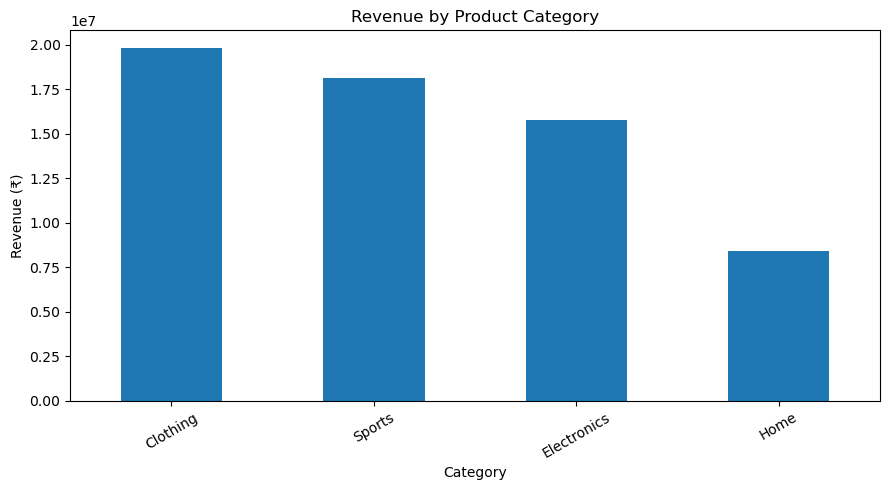

In [9]:
category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

display(category_sales)

category_sales.plot(
    kind="bar",
    title="Revenue by Product Category",
    xlabel="Category",
    ylabel="Revenue (₹)",
    figsize=(9, 5)
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

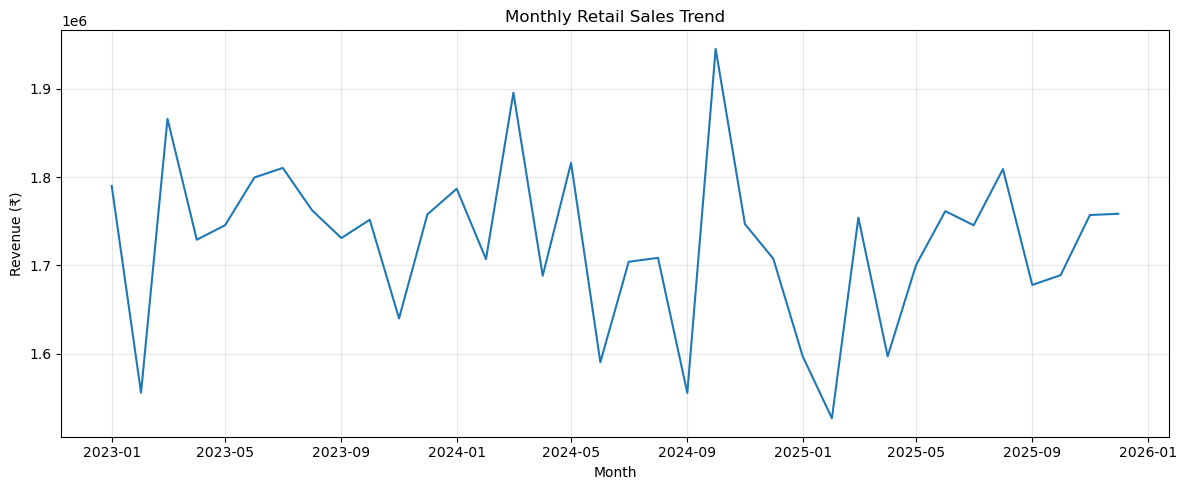

In [10]:
monthly_sales = (
    df.set_index("Order_Date")["Sales"]
      .resample("MS")
      .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

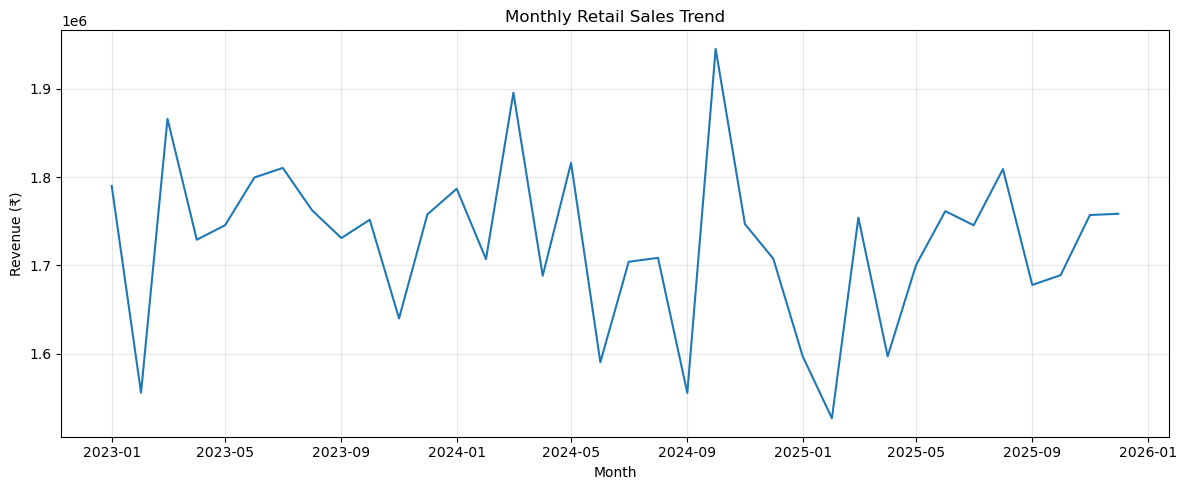

In [11]:
monthly_sales = (
    df.set_index("Order_Date")["Sales"]
      .resample("MS")
      .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

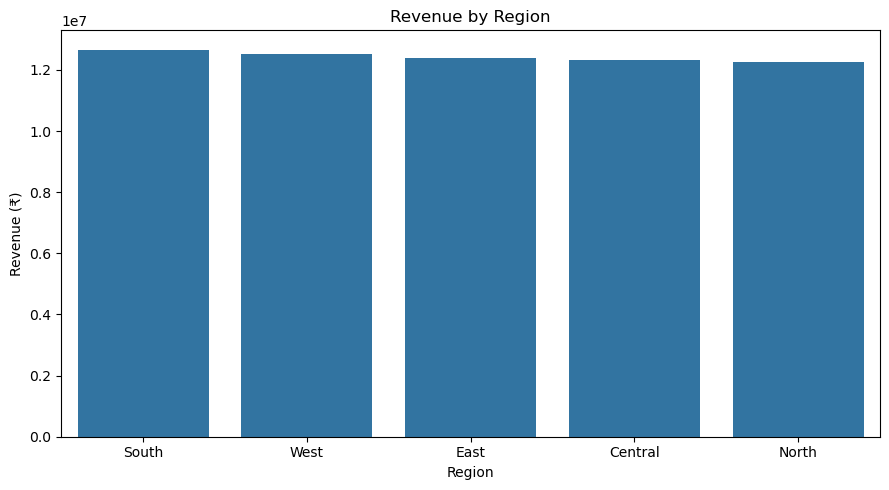

In [12]:
region_sales = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=region_sales.index, y=region_sales.values)
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (₹)")
plt.tight_layout()
plt.show()

In [13]:
daily_sales = (
    df.groupby("Order_Date")["Sales"]
      .sum()
      .sort_index()
)

# Ensure every calendar day is present
daily_sales = daily_sales.asfreq("D", fill_value=0)

display(daily_sales.head())

Order_Date
2023-01-01    57862.50
2023-01-02    61802.56
2023-01-03    68953.70
2023-01-04    87016.56
2023-01-05    57340.63
Freq: D, Name: Sales, dtype: float64

In [14]:
model_data = pd.DataFrame({
    "Sales": daily_sales
})

model_data["Day_Of_Week"] = model_data.index.dayofweek
model_data["Day_Of_Month"] = model_data.index.day
model_data["Month"] = model_data.index.month
model_data["Day_Of_Year"] = model_data.index.dayofyear

model_data["Lag_1"] = model_data["Sales"].shift(1)
model_data["Lag_7"] = model_data["Sales"].shift(7)

model_data["Rolling_Mean_7"] = (
    model_data["Sales"].shift(1).rolling(7).mean()
)

model_data = model_data.dropna()

display(model_data.head(10))

,Sales,Day_Of_Week,Day_Of_Month,Month,Day_Of_Year,Lag_1,Lag_7,Rolling_Mean_7
Order_Date,,,,,,,,
2023-01-08,45311.41,6,8,1,8,49443.28,57862.50,64460.250000
2023-01-09,50545.04,0,9,1,9,45311.41,61802.56,62667.237143
2023-01-10,37951.19,1,10,1,10,50545.04,68953.70,61059.020000
2023-01-11,51790.02,2,11,1,11,37951.19,87016.56,56630.090000
2023-01-12,66374.99,3,12,1,12,51790.02,57340.63,51597.727143
2023-01-13,50052.23,4,13,1,13,66374.99,68802.52,52888.350000
2023-01-14,40457.12,5,14,1,14,50052.23,49443.28,50209.737143
2023-01-15,46811.84,6,15,1,15,40457.12,45311.41,48926.000000
2023-01-16,66537.21,0,16,1,16,46811.84,50545.04,49140.347143


In [15]:
features = [
    "Day_Of_Week",
    "Day_Of_Month",
    "Month",
    "Day_Of_Year",
    "Lag_1",
    "Lag_7",
    "Rolling_Mean_7"
]

X = model_data[features]
y = model_data["Sales"]

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 871
Testing rows: 218


In [16]:
model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = np.maximum(
    0, model.predict(X_test)
)

print("Model training completed!")

Model training completed!


In [17]:
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

print(f"MAE: ₹{mae:,.2f}")
print(f"RMSE: ₹{rmse:,.2f}")

MAE: ₹11,480.62
RMSE: ₹14,495.24


,Actual_Sales,Predicted_Sales
Order_Date,,
2025-05-28,51774.20,52353.161735
2025-05-29,53404.34,62364.510342
2025-05-30,58059.39,62726.058218
2025-05-31,74887.68,61231.535318
2025-06-01,44157.69,58318.006338
2025-06-02,62896.04,57254.168046
2025-06-03,71135.13,54610.124765
2025-06-04,36572.16,58846.533879
2025-06-05,90998.48,45848.757627


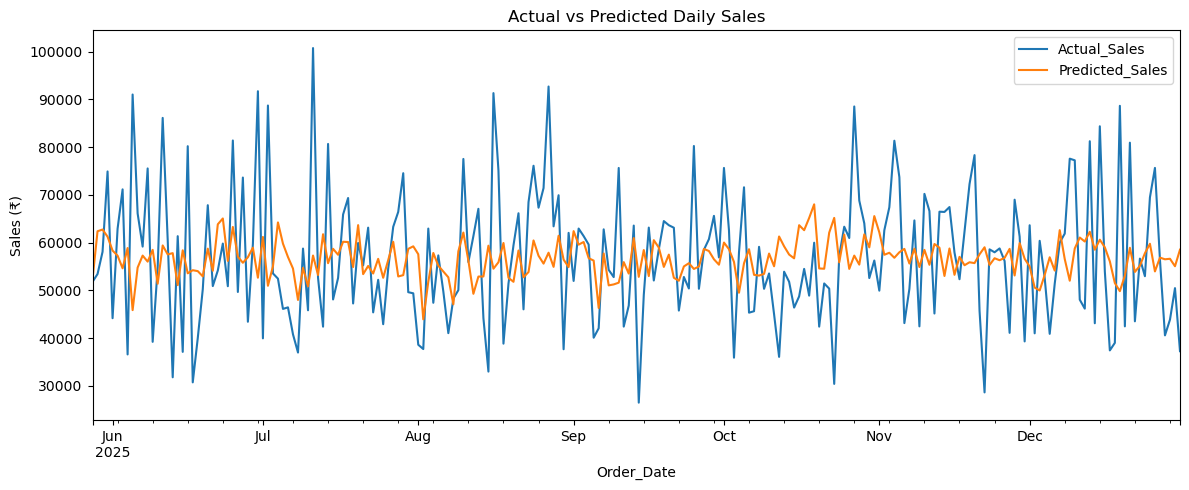

In [18]:
comparison = pd.DataFrame({
    "Actual_Sales": y_test,
    "Predicted_Sales": predictions
})

display(comparison.head(15))

comparison.plot(
    figsize=(12, 5),
    title="Actual vs Predicted Daily Sales"
)

plt.ylabel("Sales (₹)")
plt.tight_layout()
plt.show()

In [19]:
history = daily_sales.copy()
future_predictions = []

for _ in range(7):
    next_date = history.index[-1] + pd.Timedelta(days=1)

    row = pd.DataFrame([{
        "Day_Of_Week": next_date.dayofweek,
        "Day_Of_Month": next_date.day,
        "Month": next_date.month,
        "Day_Of_Year": next_date.dayofyear,
        "Lag_1": history.iloc[-1],
        "Lag_7": history.iloc[-7],
        "Rolling_Mean_7": history.iloc[-7:].mean()
    }], index=[next_date])

    predicted_sales = max(
        0, float(model.predict(row[features])[0])
    )

    future_predictions.append({
        "Date": next_date,
        "Predicted_Sales": round(predicted_sales, 2)
    })

    history.loc[next_date] = predicted_sales

forecast_df = pd.DataFrame(future_predictions)

display(forecast_df)

,Date,Predicted_Sales
0,2026-01-01,51540.58
1,2026-01-02,54954.58
2,2026-01-03,51940.35
3,2026-01-04,58466.59
4,2026-01-05,58862.21
5,2026-01-06,50874.13
6,2026-01-07,58847.14


In [20]:
df.to_csv("retail_sales_cleaned.csv", index=False)

comparison.to_csv("model_test_predictions.csv")

forecast_df.to_csv("next_7_days_forecast.csv", index=False)

print("Project outputs saved successfully!")

Project outputs saved successfully!
